<div dir="rtl">

# مشروع صغير: تحليل طلبات مطعم بمساعدة الذكاء الاصطناعي
**السؤال الرئيسي:** أين تربح إدارة المطعم، ومتى يزدحم، وما الذي يُغضب العملاء؟

**البيانات:** `restaurant_orders.csv` (طلبات 3 فروع، يناير إلى يونيو 2025). اقرأ `data_dictionary_restaurant.md` أولًا.

**المهارات المستخدمة في Cursor:** `/data-quality-report` ← `/kpi-summary` ← `/clear-charts` ← `/insight-report`

**طريقة العمل:** لكل سؤال: اطلب من Agent الكود (أو استدعِ المهارة)، اقرأ الكود قبل قبوله، شغّله، ثم قارن بنقطة التحقق.

</div>

In [2]:
# نستورد pandas لتحليل البيانات وmatplotlib لإنشاء الرسوم البيانية.
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("restaurant_orders.csv")
print(df.shape)   # نقطة تحقق: (1515, 12)
df.head()

(1515, 12)


,order_id,order_date,order_hour,branch,channel,category,item,quantity,unit_price,total,delivery_minutes,rating
0,R10001,2025-01-01,11,Downtown,Delivery,Sides,Hummus,5,3.5,17.5,43.0,3.0
1,R10002,2025-01-01,19,Mall,Takeaway,Main,Falafel Wrap,4,4.5,18.0,NaN,4.0
2,R10003,2025-01-01,20,Downtown,Dine-in,Main,Chicken Shawarma,3,6.5,19.5,NaN,NaN
3,R10004,2025-01-01,22,University,Delivery,Main,Beef Burger,2,8.0,16.0,28.0,5.0
4,R10005,2025-01-02,11,Mall,Delivery,Drinks,Fresh Juice,3,3.0,9.0,29.0,4.0


<div dir="rtl">

## الخطوة 1: فحص الجودة والتنظيف
في Agent: `/data-quality-report افحص restaurant_orders.csv` ثم: «نظّف البيانات حسب التقرير واحفظها في clean».

**نقطة تحقق:** 15 صفًا مكررًا، و6 كتابات مختلفة لأسماء الفروع، و136 تقييمًا مفقودًا. بعد التنظيف: **1500 صف** و3 فروع فقط.

</div>

In [4]:
df.info()
df.isna().sum()
df['branch']

<class 'pandas.DataFrame'>
RangeIndex: 1515 entries, 0 to 1514
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          1515 non-null   str    
 1   order_date        1515 non-null   str    
 2   order_hour        1515 non-null   int64  
 3   branch            1515 non-null   str    
 4   channel           1515 non-null   str    
 5   category          1515 non-null   str    
 6   item              1515 non-null   str    
 7   quantity          1515 non-null   int64  
 8   unit_price        1515 non-null   float64
 9   total             1515 non-null   float64
 10  delivery_minutes  378 non-null    float64
 11  rating            1379 non-null   float64
dtypes: float64(4), int64(2), str(6)
memory usage: 210.8 KB


0         Downtown
1             Mall
2         Downtown
3       University
4             Mall
           ...    
1510    University
1511      Downtown
1512          Mall
1513      Downtown
1514      Downtown
Name: branch, Length: 1515, dtype: str

In [3]:
# ننشئ نسخة منظفة ونحافظ على البيانات الأصلية في df.
clean = df.drop_duplicates().copy()
clean['branch'] = clean['branch'].str.strip().str.title()

# نتحقق من عدد الصفوف والفروع وبقاء التقييمات المفقودة.
print(f'عدد الصفوف بعد إزالة التكرار: {len(clean)}')
print(f'الفروع بعد توحيد الكتابة: {sorted(clean["branch"].unique().tolist())}')
print(f'عدد التقييمات المفقودة المحتفظ بها: {clean["rating"].isna().sum()}')


عدد الصفوف بعد إزالة التكرار: 1500
الفروع بعد توحيد الكتابة: ['Downtown', 'Mall', 'University']
عدد التقييمات المفقودة المحتفظ بها: 132


<div dir="rtl">

## الخطوة 2: مؤشرات الأداء (س1)
**س1:** ما إجمالي الإيرادات وعدد الطلبات ومتوسط قيمة الطلب ومتوسط التقييم؟ وما هي لكل فرع؟

في Agent: `/kpi-summary احسب المؤشرات العامة ثم قارن الفروع`

</div>

In [10]:
# نحسب المؤشرات العامة باستخدام نسخة البيانات المنظفة.
total_revenue = clean['total'].sum()
total_orders = clean['order_id'].nunique()
overall_kpis = pd.DataFrame({
    'المؤشر': ['إجمالي الإيرادات', 'عدد الطلبات', 'متوسط قيمة الطلب', 'متوسط التقييم'],
    'القيمة': [
        total_revenue,
        total_orders,
        total_revenue / total_orders,
        clean['rating'].mean(),
    ],
})
overall_kpis['القيمة'] = overall_kpis['القيمة'].map(lambda value: f'{value:,.2f}')
display(overall_kpis)

# نقارن المؤشرات بين الفروع ونرتبها حسب الإيرادات من الأعلى إلى الأقل.
branch_kpis = clean.groupby('branch').agg(
    الإيرادات=('total', 'sum'),
    عدد_الطلبات=('order_id', 'nunique'),
    متوسط_التقييم=('rating', 'mean'),
)
branch_kpis['متوسط_قيمة_الطلب'] = branch_kpis['الإيرادات'] / branch_kpis['عدد_الطلبات']
branch_kpis['النسبة_من_الإجمالي_%'] = branch_kpis['الإيرادات'] / total_revenue * 100
branch_kpis = branch_kpis.sort_values('الإيرادات', ascending=False)
branch_table = branch_kpis.rename(columns={
    'الإيرادات': 'الإيرادات ($)',
    'عدد_الطلبات': 'عدد الطلبات',
    'متوسط_قيمة_الطلب': 'متوسط قيمة الطلب ($)',
    'متوسط_التقييم': 'متوسط التقييم',
    'النسبة_من_الإجمالي_%': 'النسبة من الإجمالي %',
})
display(branch_table.style.format({
    'الإيرادات ($)': '{:,.2f}',
    'عدد الطلبات': '{:,.2f}',
    'متوسط قيمة الطلب ($)': '{:,.2f}',
    'متوسط التقييم': '{:,.2f}',
    'النسبة من الإجمالي %': '{:.2f}%',
}))

# نعرض أعلى فرع وأقل فرع والفرق بينهما دون تفسير الأسباب.
highest_branch = branch_kpis.iloc[0]
lowest_branch = branch_kpis.iloc[-1]
print(f'أعلى فرع إيرادًا: {branch_kpis.index[0]} — {highest_branch["الإيرادات"]:,.2f} دولار')
print(f'أقل فرع إيرادًا: {branch_kpis.index[-1]} — {lowest_branch["الإيرادات"]:,.2f} دولار')
print(f'الفرق بينهما: {highest_branch["الإيرادات"] - lowest_branch["الإيرادات"]:,.2f} دولار')

# نتحقق من أن مجموع إيرادات الفروع يساوي الإيراد العام.
assert abs(branch_kpis['الإيرادات'].sum() - total_revenue) < 0.01
print(f'التحقق: مجموع إيرادات الفروع يساوي الإجمالي العام ({branch_kpis["الإيرادات"].sum():,.2f} دولار).')


,المؤشر,القيمة
0,إجمالي الإيرادات,"18,751.00"
1,عدد الطلبات,"1,500.00"
2,متوسط قيمة الطلب,12.50
3,متوسط التقييم,4.07


,الإيرادات ($),عدد الطلبات,متوسط التقييم,متوسط قيمة الطلب ($),النسبة من الإجمالي %
branch,,,,,
Mall,"7,933.00",590.00,4.12,13.45,42.31%
Downtown,"6,678.00",466.00,4.01,14.33,35.61%
University,"4,140.00",444.00,4.04,9.32,22.08%


أعلى فرع إيرادًا: Mall — 7,933.00 دولار
أقل فرع إيرادًا: University — 4,140.00 دولار
الفرق بينهما: 3,793.00 دولار
التحقق: مجموع إيرادات الفروع يساوي الإجمالي العام (18,751.00 دولار).


<div dir="rtl">

## الخطوة 3: الذروة والقنوات والأصناف (س2، س3، س4)
- **س2:** ما ساعات الذروة؟ وأي أيام الأسبوع أكثر ازدحامًا؟
- **س3:** ما حصة كل قناة (صالة، سفري، توصيل) من الإيرادات؟
- **س4:** ما أعلى 5 أصناف من حيث الإيرادات؟

ارسم رسمين على الأقل باستخدام `/clear-charts`.

</div>

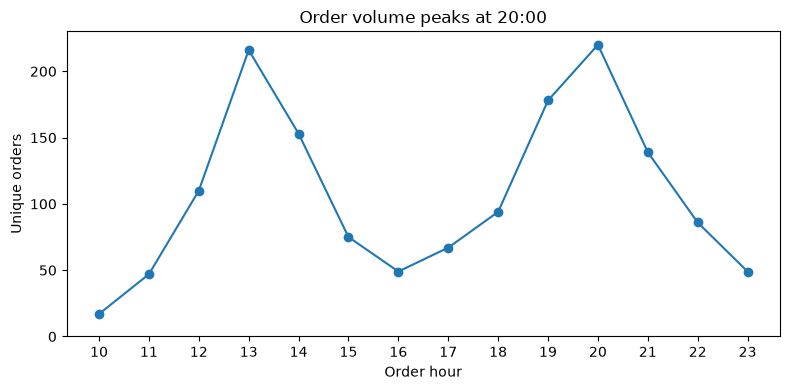

            Unique orders
order_hour               
10                     17
11                     47
12                    110
13                    216
14                    153
15                     75
16                     49
17                     67
18                     94
19                    178
20                    220
21                    139
22                     86
23                     49


In [5]:
# نلخص عدد الطلبات الفريدة حسب ساعة الطلب ونرسم اتجاه الازدحام خلال اليوم.
hourly_orders = clean.groupby('order_hour')['order_id'].nunique().sort_index()
ax = hourly_orders.plot(kind='line', marker='o', figsize=(8, 4), color='#1f77b4')
ax.set_title('Order volume peaks at 20:00')
ax.set_xlabel('Order hour')
ax.set_ylabel('Unique orders')
ax.set_xticks(hourly_orders.index)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()
print(hourly_orders.rename('Unique orders').to_frame().to_string())


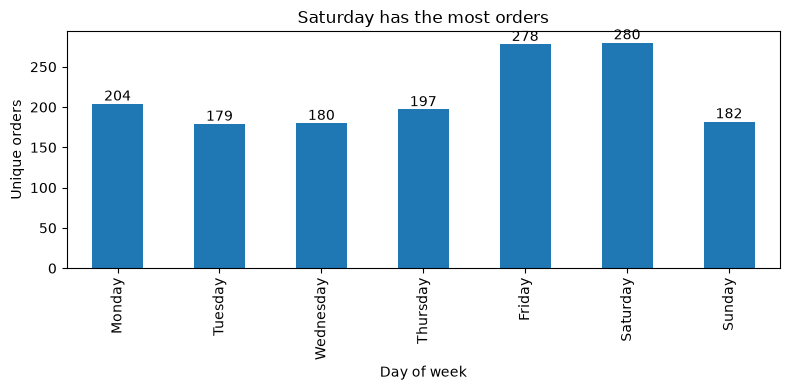

           Unique orders
weekday                 
Monday               204
Tuesday              179
Wednesday            180
Thursday             197
Friday               278
Saturday             280
Sunday               182


In [6]:
# نرتب أيام الأسبوع ترتيبًا زمنيًا ونقارن عدد الطلبات الفريدة.
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_orders = (
    clean.assign(weekday=pd.to_datetime(clean['order_date']).dt.day_name())
    .groupby('weekday')['order_id'].nunique()
    .reindex(weekday_order)
)
ax = weekday_orders.plot(kind='bar', figsize=(8, 4), color='#1f77b4')
ax.set_title('Saturday has the most orders')
ax.set_xlabel('Day of week')
ax.set_ylabel('Unique orders')
ax.set_ylim(bottom=0)
for bar in ax.patches:
    ax.annotate(f'{bar.get_height():.0f}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()
print(weekday_orders.rename('Unique orders').to_frame().to_string())


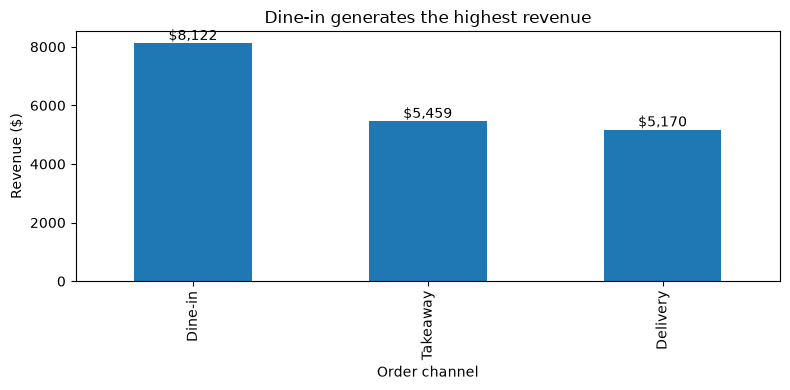

          Revenue ($)
channel              
Dine-in        8122.0
Takeaway       5459.0
Delivery       5170.0


In [7]:
# نقارن إيرادات قنوات الطلب ونطبع القيم نفسها للتحقق من الرسم.
channel_revenue = clean.groupby('channel')['total'].sum().sort_values(ascending=False)
ax = channel_revenue.plot(kind='bar', figsize=(8, 4), color='#1f77b4')
ax.set_title('Dine-in generates the highest revenue')
ax.set_xlabel('Order channel')
ax.set_ylabel('Revenue ($)')
ax.set_ylim(bottom=0)
for bar in ax.patches:
    ax.annotate(f'${bar.get_height():,.0f}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()
print(channel_revenue.rename('Revenue ($)').to_frame().to_string())


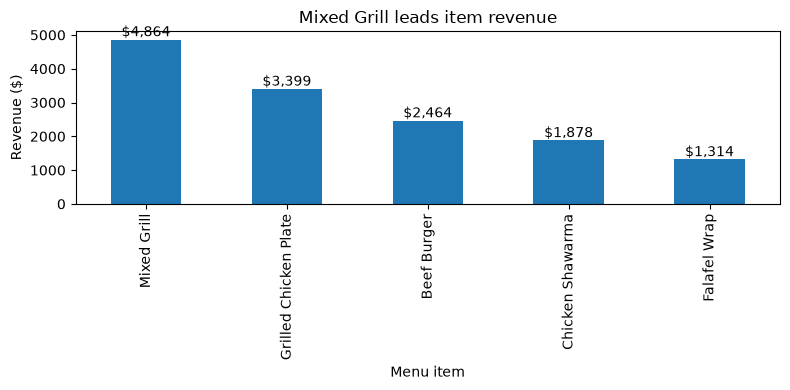

                       Revenue ($)
item                              
Mixed Grill                 4864.0
Grilled Chicken Plate       3399.0
Beef Burger                 2464.0
Chicken Shawarma            1878.5
Falafel Wrap                1314.0


In [8]:
# نعرض أعلى خمسة أصناف من حيث الإيرادات بترتيب تنازلي.
top_items_revenue = clean.groupby('item')['total'].sum().nlargest(5).sort_values(ascending=False)
ax = top_items_revenue.plot(kind='bar', figsize=(8, 4), color='#1f77b4')
ax.set_title('Mixed Grill leads item revenue')
ax.set_xlabel('Menu item')
ax.set_ylabel('Revenue ($)')
ax.set_ylim(bottom=0)
for bar in ax.patches:
    ax.annotate(f'${bar.get_height():,.0f}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()
print(top_items_revenue.rename('Revenue ($)').to_frame().to_string())


<div dir="rtl">

## الخطوة 4: رضا العملاء (س5)
**س5:** هل يرتبط وقت التوصيل بتقييم العميل؟
قسّم طلبات التوصيل إلى ثلاث فئات: أقل من 30 دقيقة، من 30 إلى 45، أكثر من 45. ثم احسب عدد الطلبات ومتوسط التقييم لكل فئة.

> هذه مقارنة بين متوسطات، لا تحتاج أي نموذج تعلم آلي. لكنها لا تثبت السبب وحدها.

</div>

In [9]:
# نحلل طلبات التوصيل فقط، ونقسم زمنها إلى الفئات المطلوبة.
delivery_orders = clean.loc[clean['channel'].eq('Delivery')].copy()
delivery_orders['فئة زمن التوصيل'] = ''
delivery_orders.loc[delivery_orders['delivery_minutes'] < 30, 'فئة زمن التوصيل'] = 'أقل من 30 دقيقة'
delivery_orders.loc[
    delivery_orders['delivery_minutes'].between(30, 45, inclusive='both'),
    'فئة زمن التوصيل',
] = 'من 30 إلى 45 دقيقة'
delivery_orders.loc[delivery_orders['delivery_minutes'] > 45, 'فئة زمن التوصيل'] = 'أكثر من 45 دقيقة'

# نحسب عدد الطلبات الفريدة ومتوسط التقييم، مع استبعاد التقييمات المفقودة من المتوسط.
delivery_rating_summary = delivery_orders.groupby('فئة زمن التوصيل', sort=False).agg(
    عدد_الطلبات=('order_id', 'nunique'),
    عدد_التقييمات=('rating', 'count'),
    متوسط_التقييم=('rating', 'mean'),
).reindex(['أقل من 30 دقيقة', 'من 30 إلى 45 دقيقة', 'أكثر من 45 دقيقة'])
display(delivery_rating_summary.round(2))


,عدد_الطلبات,عدد_التقييمات,متوسط_التقييم
فئة زمن التوصيل,,,
أقل من 30 دقيقة,69,61,4.11
من 30 إلى 45 دقيقة,200,185,3.59
أكثر من 45 دقيقة,105,94,2.47


<div dir="rtl">

## الخطوة 5: الرؤى والتوصيات (س6)
في Agent: `/insight-report اكتب الرؤى والتوصيات من نتائج هذا الدفتر واحفظها في insights.md`

ثم راجع: هل كل رقم في التقرير موجود فعلًا في مخرجات الدفتر؟ سجّل أي خطأ في سجل التحقق أدناه.

## سجل التحقق
| ماذا قال الذكاء الاصطناعي | كيف تحققت | النتيجة |
| --- | --- | --- |
|  |  |  |

</div>